# 07. Mô Hình Deep Learning Thị Giác Máy Tính — ResNet-18 Phân Độ Võng Mạc (`cnn_retinopathy_resnet18.pt`)
Mô hình **ResNet-18** tinh chỉnh trên ảnh chụp đáy mắt màu (RetinaMNIST 5 mức độ ICDR 0–4) kèm bản đồ nhiệt **Grad-CAM** ở tầng `layer4` cho `CNNRetinopathyEngine`. Artifact lưu tại `/notebook/model/cnn_retinopathy_resnet18.pt`.

Artifact: notebook/model/cnn_retinopathy_resnet18.pt (44.79 MB)
Nhãn dự đoán: 0 – Không có bệnh võng mạc ĐTĐ | Xác suất: [0.3914, 0.0986, 0.0774, 0.1581, 0.2744]
Khuyến nghị lâm sàng: Khám lại mắt sau 1–2 năm nếu đường huyết kiểm soát tốt (ADA 2024).


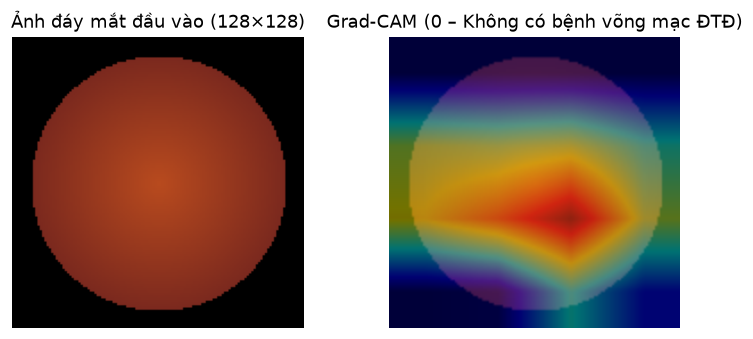

In [1]:
import base64
import io
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from src.models.cnn_vision import DR_CLASSES, MODEL_PATH, get_grader

grader = get_grader()
print(f"Artifact: {MODEL_PATH.relative_to(ROOT)} ({MODEL_PATH.stat().st_size / 1e6:.2f} MB)")

# Tạo ảnh giả lập võng mạc & chạy phân độ + trích xuất bản đồ nhiệt Grad-CAM
yy, xx = np.mgrid[-64:64, -64:64]
radius = np.sqrt(xx**2 + yy**2)
img = np.zeros((128, 128, 3), dtype=np.uint8)
mask = radius < 56
img[mask, 0] = np.clip(185 - radius[mask] * 1.1, 40, 230).astype(np.uint8)
img[mask, 1] = np.clip(75 - radius[mask] * 0.6, 15, 120).astype(np.uint8)
img[mask, 2] = 30

buf = io.BytesIO()
Image.fromarray(img).save(buf, format="PNG")
res = grader.predict(buf.getvalue(), with_cam=True)
print("Nhãn dự đoán:", res["label"], "| Xác suất:", res["probabilities"])
print("Khuyến nghị lâm sàng:", res["advice"])

cam_img = Image.open(io.BytesIO(base64.b64decode(res["gradcam_png"])))
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
axes[0].imshow(img)
axes[0].set_title("Ảnh đáy mắt đầu vào (128×128)")
axes[0].axis("off")
axes[1].imshow(cam_img)
axes[1].set_title(f"Grad-CAM ({res['label']})")
axes[1].axis("off")
plt.tight_layout()
